# Assignment 5: Comparing representations across two layers of an MNIST network
Audrey and Kevin

We train a small MLP (784 → 256 → 64 → 10) and compare hidden layer 1 (256 units) with hidden layer 2 (64 units) using PCA, t-SNE, tuning curves and RDMs.

In [1]:
import numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
from torchvision import datasets, transforms
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.stats import spearmanr

torch.manual_seed(0); np.random.seed(0)
tf = transforms.ToTensor()
train = datasets.MNIST('data', train=True, download=True, transform=tf)
test = datasets.MNIST('data', train=False, download=True, transform=tf)
loader = torch.utils.data.DataLoader(train, batch_size=128, shuffle=True)

net = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(),
                    nn.Linear(256, 64), nn.ReLU(), nn.Linear(64, 10))
opt = torch.optim.Adam(net.parameters(), lr=1e-3)
for epoch in range(3):
    for x, y in loader:
        opt.zero_grad(); nn.functional.cross_entropy(net(x), y).backward(); opt.step()

X = test.data[:2000].float().unsqueeze(1) / 255; y = test.targets[:2000].numpy()
with torch.no_grad():
    print('test accuracy:', (net(X).argmax(1).numpy() == y).mean())
    h1 = net[:3](X).numpy()   # hidden layer 1 (after ReLU)
    h2 = net[:5](X).numpy()   # hidden layer 2 (after ReLU)

test accuracy: 0.959


C:\Users\T430\AppData\Local\Temp\ipykernel_16180\2534668913.py:14: RuntimeWarning: invalid value encountered in divide
  return m[:, act], ((best - rest) / (best + rest))[act]


C:\Users\T430\AppData\Local\Temp\ipykernel_16180\2534668913.py:14: RuntimeWarning: invalid value encountered in divide
  return m[:, act], ((best - rest) / (best + rest))[act]


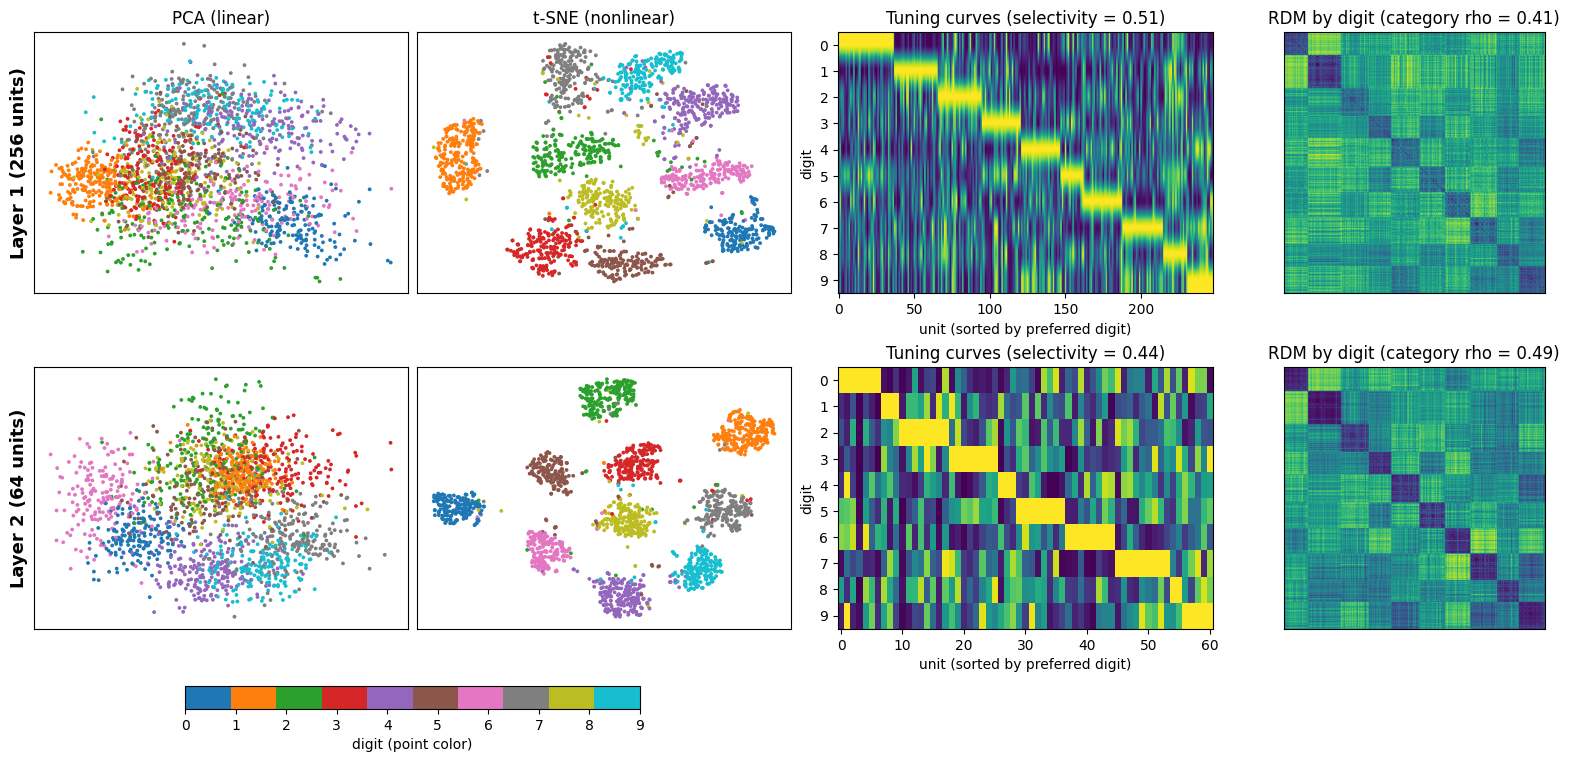

Layer 1 (256 units) {'selectivity': 0.51, 'category_rho': 0.41, 'active_units': 248.0, 'pcs_for_90pct': 27.0}
Layer 2 (64 units) {'selectivity': 0.44, 'category_rho': 0.49, 'active_units': 61.0, 'pcs_for_90pct': 8.0}
RDM similarity between layers (Spearman): 0.81


In [2]:
layers = {'Layer 1 (256 units)': h1, 'Layer 2 (64 units)': h2}
# 600 random test images, sorted by digit, for the RDMs
sub =np.sort(np.random.choice(len(y), 600, replace=False)); sub = sub[np.argsort(y[sub], kind='stable')]
category = (y[sub][:, None] != y[sub][None, :]).astype(float)  # model RDM: 0 same digit, 1 different
iu = np.triu_indices(len(sub), 1)

def rdm(a):
    return 1 - np.corrcoef(a)  # correlation distance

def selectivity(a):
    m = np.array([a[y == d].mean(0) for d in range(10)])  # digit x unit tuning curves
    act = m.max(0) > 1e-6
    best, rest = m.max(0), (m.sum(0) - m.max(0)) / 9
    return m[:, act], ((best - rest) / (best + rest))[act]

fig, ax = plt.subplots(2, 4, figsize=(16, 7.5), layout='constrained')
rdms, stats = {}, {}
for r, (name, a) in enumerate(layers.items()):
    for c, (emb, title) in enumerate([(PCA(2).fit_transform(a), 'PCA (linear)'),
                                      (TSNE(2, random_state=0, init='pca').fit_transform(a), 't-SNE (nonlinear)')]):
        sc = ax[r, c].scatter(*emb.T, c=y, cmap='tab10', s=3)
        ax[r, c].set(title=title if r == 0 else '', xticks=[], yticks=[])
    ax[r, 0].set_ylabel(name, fontsize=13, fontweight='bold')
    m, sel = selectivity(a)
    m = m[:, np.argsort(m.argmax(0))]
    ax[r, 2].imshow((m / m.max(0)), aspect='auto', cmap='viridis')
    ax[r, 2].set(title=f'Tuning curves (selectivity = {sel.mean():.2f})', xlabel='unit (sorted by preferred digit)', ylabel='digit', yticks=range(10))
    rdms[name] = rdm(a[sub])
    ax[r, 3].imshow(rdms[name], cmap='viridis')
    rho = spearmanr(rdms[name][iu], category[iu])[0]
    ax[r, 3].set(title=f'RDM by digit (category rho = {rho:.2f})', xticks=[], yticks=[])
    stats[name] = dict(selectivity=sel.mean(), category_rho=rho, active_units=m.shape[1],
                       pcs_for_90pct=int(np.searchsorted(np.cumsum(PCA().fit(a).explained_variance_ratio_), 0.9) + 1))
fig.colorbar(sc, ax=ax[1, :2], ticks=range(10), label='digit (point color)', orientation='horizontal', shrink=0.6)
plt.savefig('mnist_layers.png', dpi=150, bbox_inches='tight'); plt.show()

r12 = spearmanr(*(d[iu] for d in rdms.values()))[0]
for k, v in stats.items(): print(k, {s: round(float(x), 2) for s, x in v.items()})
print('RDM similarity between layers (Spearman):', round(r12, 2))

## What changed from layer 1 to layer 2?
- **Compression:** layer 2 needs far fewer dimensions (8 vs. 27 PCs for 90% of variance).
- **Geometry becomes more categorical:** the RDM matches the digit-category model better (rho 0.41 to 0.49), and the t-SNE clusters are cleaner.
- **Tuning becomes less selective:** individual layer-2 units respond to several digits (selectivity 0.51 to 0.44), so category information moves from single units into the population pattern.
- **Overall:** the transformation is a nonlinear (ReLU) compression that keeps most of the geometry (RDM similarity between layers = 0.81) while pulling same-digit images together. This matches Kriegeskorte & Wei: tuning and geometry can change in different ways.